<div style="text-align: center;">
  <h1 style="font-size: 30px; font-weight: bold;">
    H03e - A rotating Smartphone as an accelerated Frame of Reference
  </h1>
</div>

<div style="text-align: center;">
  <h1 style="font-size: 15px; font-weight: bold;">
    Group 6 - Syed Muhammad Haider Amir (50%), Laiba Rehan Zahid (50%)
  </h1>
</div>

<div style="text-align: center;">
  <h1 style="font-size: 15px; font-weight: bold;">
    Date: 28.10.2025
  </h1>
</div>

---

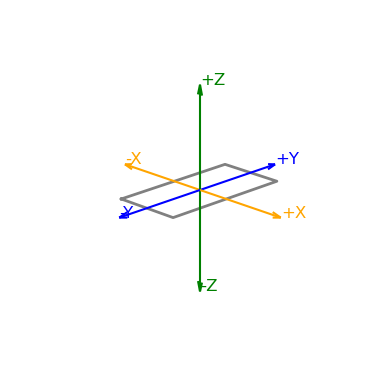

In [9]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111, projection='3d')

# Rectangle (representing the phone screen in the XY plane)
x_rect = [-1, 1, 1, -1, -1]
y_rect = [-2, -2, 2, 2, -2]
z_rect = [0, 0, 0, 0, 0]  # flat at z=0
ax.plot(x_rect, y_rect, z_rect, color='gray', linewidth=2)

axis_length = 3

# +X and -X (orange)
ax.quiver(0, 0, 0, axis_length, 0, 0, color='orange', arrow_length_ratio=0.1)
ax.quiver(0, 0, 0, -axis_length, 0, 0, color='orange', arrow_length_ratio=0.1)

# +Y and -Y (blue)
ax.quiver(0, 0, 0, 0, axis_length, 0, color='blue', arrow_length_ratio=0.1)
ax.quiver(0, 0, 0, 0, -axis_length, 0, color='blue', arrow_length_ratio=0.1)

# +Z and -Z (green)
ax.quiver(0, 0, 0, 0, 0, axis_length, color='green', arrow_length_ratio=0.1)
ax.quiver(0, 0, 0, 0, 0, -axis_length, color='green', arrow_length_ratio=0.1)

# Labels
ax.text(axis_length, 0, 0, '+X', color='orange', fontsize=12)
ax.text(-axis_length, 0, 0, '-X', color='orange', fontsize=12)
ax.text(0, axis_length, 0, '+Y', color='blue', fontsize=12)
ax.text(0, -axis_length, 0, '-Y', color='blue', fontsize=12)
ax.text(0, 0, axis_length, '+Z', color='green', fontsize=12)
ax.text(0, 0, -axis_length, '-Z', color='green', fontsize=12)

# Set equal aspect ratio
ax.set_box_aspect([1, 1, 1])

# Adjust limits
ax.set_xlim([-3, 3])
ax.set_ylim([-3, 3])
ax.set_zlim([-3, 3])

# Set viewing angle so it looks like the phone image
ax.view_init(elev=20, azim=-45)

ax.set_axis_off()
plt.tight_layout()
plt.savefig("plot1.png", dpi=300, bbox_inches="tight")
plt.show()


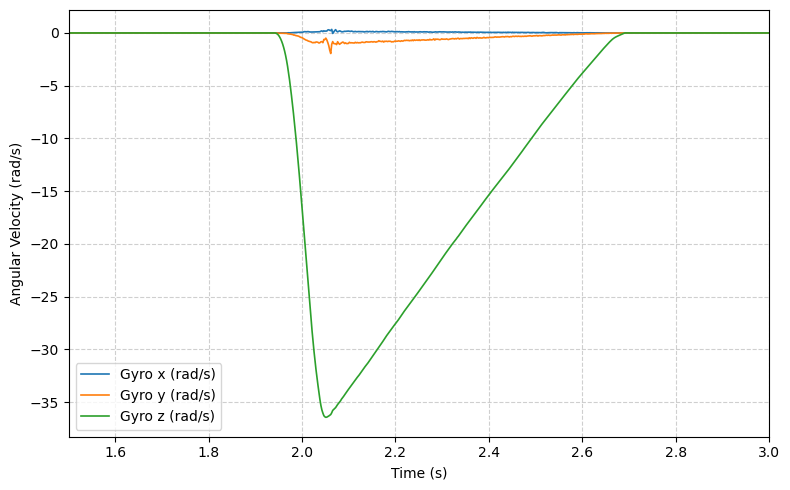

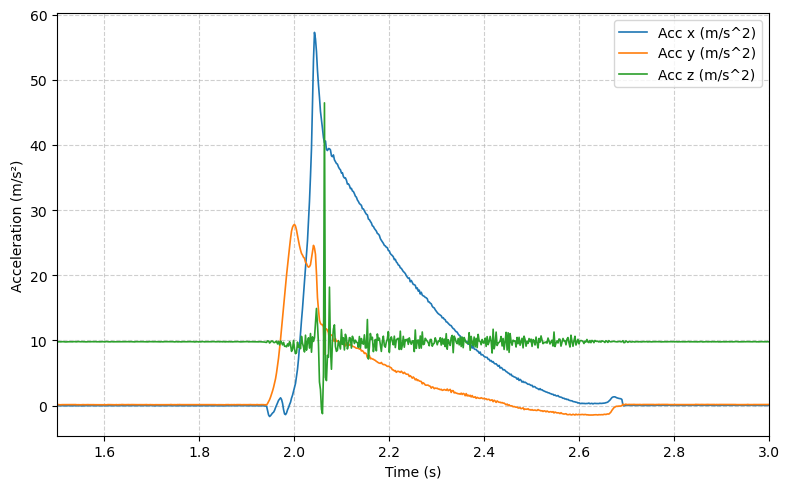

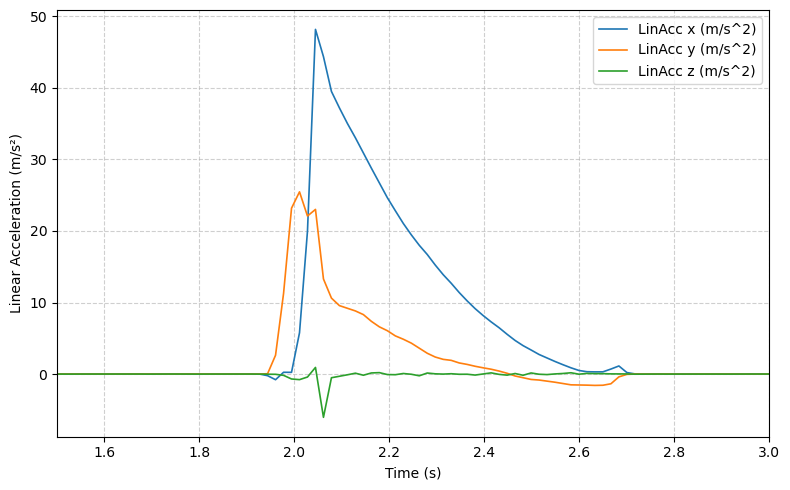

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load and clean the data ===
data = pd.read_csv("Exp 1 (trial 3).csv")

# Extract gyroscope data
gyro = data.iloc[1:, 0:4].copy()
gyro.columns = ["Time (s)", "Gyro x (rad/s)", "Gyro y (rad/s)", "Gyro z (rad/s)"]
gyro = gyro.apply(pd.to_numeric, errors="coerce").dropna()

# Extract linear acceleration data
lin_acc = data.iloc[1:, 5:9].copy()
lin_acc.columns = ["Time (s)", "LinAcc x (m/s^2)", "LinAcc y (m/s^2)", "LinAcc z (m/s^2)"]
lin_acc = lin_acc.apply(pd.to_numeric, errors="coerce").dropna()

# Extract total acceleration data
acc = data.iloc[1:, 10:14].copy()
acc.columns = ["Time (s)", "Acc x (m/s^2)", "Acc y (m/s^2)", "Acc z (m/s^2)"]
acc = acc.apply(pd.to_numeric, errors="coerce").dropna()

# === Define a function for consistent plotting and saving ===
def plot_sensor_data(df, cols, ylabel, xlim=(1.5, 3.0), save_path=None):
    plt.figure(figsize=(8, 5))
    for col in cols:
        plt.plot(df["Time (s)"], df[col], label=col, linewidth=1.2)
    plt.xlabel("Time (s)")
    plt.ylabel(ylabel)
    plt.xlim(xlim)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show    

# === Plot 1: Angular Velocity (Gyroscope) ===
plot_sensor_data(
    gyro,
    ["Gyro x (rad/s)", "Gyro y (rad/s)", "Gyro z (rad/s)"],
    "Angular Velocity (rad/s)",
    save_path="gyro_plot.png"
)
# === Plot 2: Acceleration ===
plot_sensor_data(
    acc,
    ["Acc x (m/s^2)", "Acc y (m/s^2)", "Acc z (m/s^2)"],
    "Acceleration (m/s²)",
    save_path="acc_plot.png"
)

# === Plot 3: Linear Acceleration (without g) ===
plot_sensor_data(
    lin_acc,
    ["LinAcc x (m/s^2)", "LinAcc y (m/s^2)", "LinAcc z (m/s^2)"],
    "Linear Acceleration (m/s²)",
    save_path="lin_acc_plot.png"
)

=== Sensor Coordinates (relative to rotation axis) ===
r_x = 32.01 ± 0.17 mm
r_y = 11.09 ± 0.17 mm


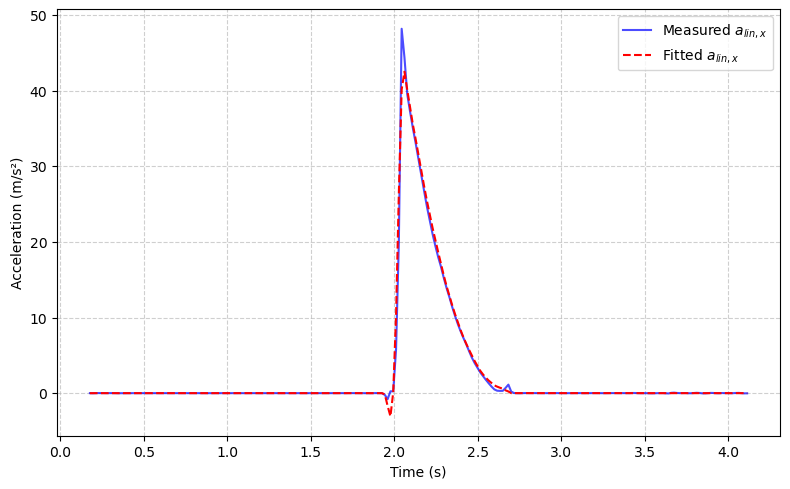

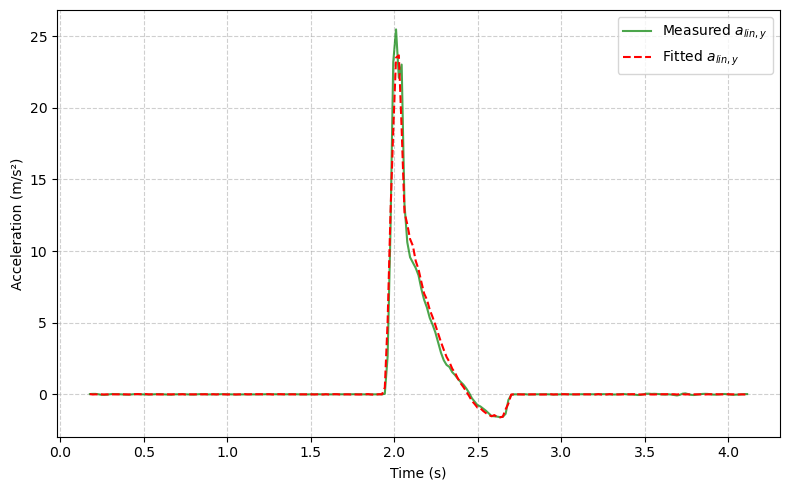

In [11]:
# === H03e Curve Fitting: Determine Sensor Coordinates ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# === Step 1. Load and structure the data ===
data = pd.read_csv("Exp 1 (trial 3).csv")

# Extract relevant columns
gyro = data.iloc[1:, 0:4].copy()
gyro.columns = ["Time (s)", "Gyro x (rad/s)", "Gyro y (rad/s)", "Gyro z (rad/s)"]
gyro = gyro.apply(pd.to_numeric, errors="coerce").dropna()

lin_acc = data.iloc[1:, 5:9].copy()
lin_acc.columns = ["Time (s)", "LinAcc x (m/s^2)", "LinAcc y (m/s^2)", "LinAcc z (m/s^2)"]
lin_acc = lin_acc.apply(pd.to_numeric, errors="coerce").dropna()

# Synchronize time intervals (truncate to common range)
min_time = max(gyro["Time (s)"].min(), lin_acc["Time (s)"].min())
max_time = min(gyro["Time (s)"].max(), lin_acc["Time (s)"].max())

gyro = gyro[(gyro["Time (s)"] >= min_time) & (gyro["Time (s)"] <= max_time)]
lin_acc = lin_acc[(lin_acc["Time (s)"] >= min_time) & (lin_acc["Time (s)"] <= max_time)]

# === Step 2. Compute angular acceleration alpha_z ===
omega_z = gyro["Gyro z (rad/s)"].to_numpy()
time = gyro["Time (s)"].to_numpy()
alpha_z = np.gradient(omega_z, time)

# Interpolate omega_z and alpha_z to match lin_acc time points
from scipy.interpolate import interp1d
interp_omega = interp1d(time, omega_z, fill_value="extrapolate")
interp_alpha = interp1d(time, alpha_z, fill_value="extrapolate")

omega_z_interp = interp_omega(lin_acc["Time (s)"].to_numpy())
alpha_z_interp = interp_alpha(lin_acc["Time (s)"].to_numpy())

# === Step 3. Define theoretical model for a_lin_x and a_lin_y ===
def model_a_lin(params, omega, alpha):
    r_x, r_y = params
    a_lin_x = omega**2 * r_x + alpha * r_y
    a_lin_y = omega**2 * r_y - alpha * r_x
    return a_lin_x, a_lin_y

# === Step 4. Prepare measured data ===
a_lin_x_meas = lin_acc["LinAcc x (m/s^2)"].to_numpy()
a_lin_y_meas = lin_acc["LinAcc y (m/s^2)"].to_numpy()

# === Step 5. Define residual function for fitting ===
def residuals(params, omega, alpha, ax_meas, ay_meas):
    ax_pred, ay_pred = model_a_lin(params, omega, alpha)
    return np.concatenate([(ax_meas - ax_pred), (ay_meas - ay_pred)])

# Initial guess
initial_guess = [0.03, 0.01]  # in meters

# Use least squares optimization
from scipy.optimize import least_squares
res = least_squares(residuals, initial_guess,
                    args=(omega_z_interp, alpha_z_interp, a_lin_x_meas, a_lin_y_meas))

r_x, r_y = res.x

# === Step 6. Estimate uncertainties from covariance matrix ===
# Approximate covariance as (J^T J)^-1 * residual_variance
J = res.jac
residual_var = np.sum(res.fun**2) / (len(res.fun) - len(res.x))
cov = np.linalg.inv(J.T @ J) * residual_var
uncertainties = np.sqrt(np.diag(cov))
r_x_err, r_y_err = uncertainties

# === Step 7. Compute fitted model curves ===
a_lin_x_fit, a_lin_y_fit = model_a_lin([r_x, r_y], omega_z_interp, alpha_z_interp)

# === Step 8. Print final results ===
print("=== Sensor Coordinates (relative to rotation axis) ===")
print(f"r_x = {r_x*1000:.2f} ± {r_x_err*1000:.2f} mm")
print(f"r_y = {r_y*1000:.2f} ± {r_y_err*1000:.2f} mm")

# === Step 9. Plot measured vs fitted data ===
plt.figure(figsize=(8, 5))
plt.plot(lin_acc["Time (s)"], a_lin_x_meas, 'b', label='Measured $a_{lin,x}$', alpha=0.7)
plt.plot(lin_acc["Time (s)"], a_lin_x_fit, 'r--', label='Fitted $a_{lin,x}$')
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("plot2.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(lin_acc["Time (s)"], a_lin_y_meas, 'g', label='Measured $a_{lin,y}$', alpha=0.7)
plt.plot(lin_acc["Time (s)"], a_lin_y_fit, 'r--', label='Fitted $a_{lin,y}$')
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("plot3.png", dpi=300, bbox_inches="tight")
plt.show()

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


C:\Users\laiba\anaconda3\Lib\site-packages\pysr\sr.py:1036: FutureWarning: `loss` has been renamed to `elementwise_loss` in PySRRegressor. Please use that instead.
  warnings.warn(


Running symbolic regression for a_lin_x ...


C:\Users\laiba\anaconda3\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(


Running symbolic regression for a_lin_y ...


C:\Users\laiba\anaconda3\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(



Best equation for a_lin_x:
complexity                                                       9
loss                                                       0.54457
equation          ((x0 * 0.031804275) - (x1 * 0.00065642025)) * x0
score                                                     0.445696
sympy_format                x0*(x0*0.031804275 - 0.00065642025*x1)
lambda_format    PySRFunction(X=>x0*(x0*0.031804275 - 0.0006564...
Name: 4, dtype: object

Best equation for a_lin_y:
complexity                                                       9
loss                                                      0.241347
equation             ((x0 * 0.010966486) * x0) - (x1 * 0.03504338)
score                                                     0.558554
sympy_format                     x0*0.010966486*x0 - 0.03504338*x1
lambda_format    PySRFunction(X=>x0*0.010966486*x0 - 0.03504338...
Name: 4, dtype: object

=== Symbolic Regression Results ===
r_x = 31.84 ± 0.20 mm
r_y = 10.97 ± 0.12 mm


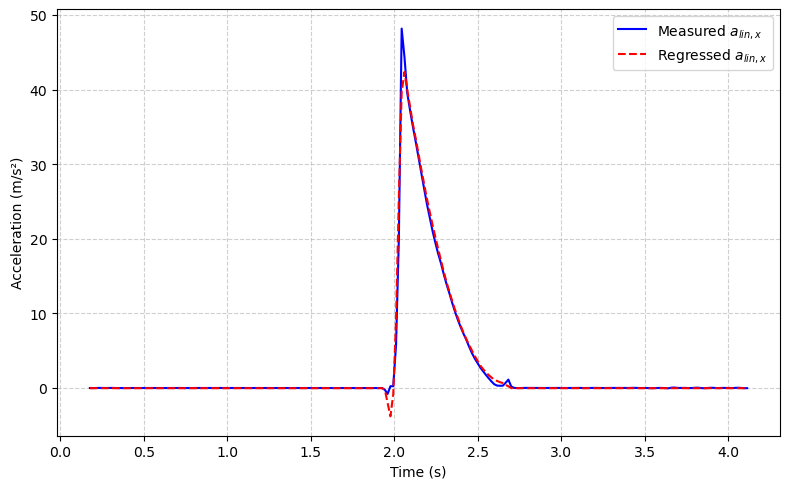

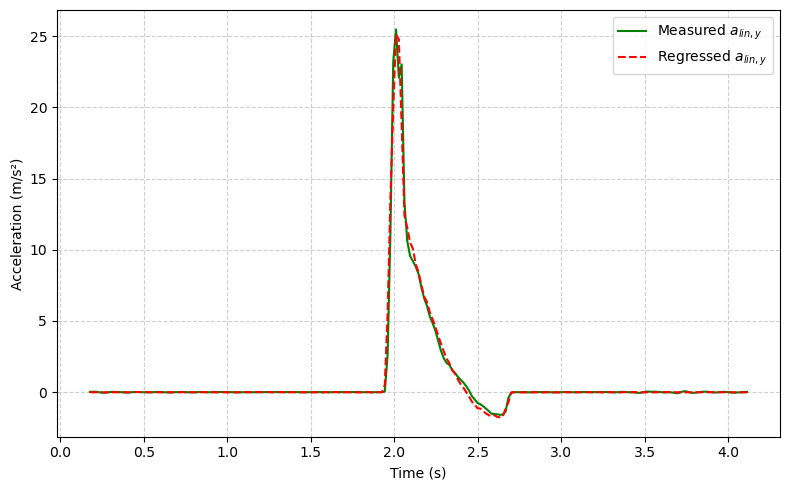

In [12]:
# === H03e Symbolic Regression: Determining Sensor Coordinates ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pysr import PySRRegressor
from sympy import symbols

# === Step 1. Load and prepare the data ===
data = pd.read_csv("Exp 1 (trial 3).csv")

gyro = data.iloc[1:, 0:4].copy()
gyro.columns = ["Time (s)", "Gyro x (rad/s)", "Gyro y (rad/s)", "Gyro z (rad/s)"]
gyro = gyro.apply(pd.to_numeric, errors="coerce").dropna()

lin_acc = data.iloc[1:, 5:9].copy()
lin_acc.columns = ["Time (s)", "LinAcc x (m/s^2)", "LinAcc y (m/s^2)", "LinAcc z (m/s^2)"]
lin_acc = lin_acc.apply(pd.to_numeric, errors="coerce").dropna()

# Synchronize time intervals
min_time = max(gyro["Time (s)"].min(), lin_acc["Time (s)"].min())
max_time = min(gyro["Time (s)"].max(), lin_acc["Time (s)"].max())

gyro = gyro[(gyro["Time (s)"] >= min_time) & (gyro["Time (s)"] <= max_time)]
lin_acc = lin_acc[(lin_acc["Time (s)"] >= min_time) & (lin_acc["Time (s)"] <= max_time)]

# Compute alpha_z = dω_z/dt
omega_z = gyro["Gyro z (rad/s)"].to_numpy()
time = gyro["Time (s)"].to_numpy()
alpha_z = np.gradient(omega_z, time)

# Interpolate to match lin_acc time points
from scipy.interpolate import interp1d
interp_omega = interp1d(time, omega_z, fill_value="extrapolate")
interp_alpha = interp1d(time, alpha_z, fill_value="extrapolate")

omega_z_interp = interp_omega(lin_acc["Time (s)"].to_numpy())
alpha_z_interp = interp_alpha(lin_acc["Time (s)"].to_numpy())

# Create input features and targets
X = np.column_stack([omega_z_interp, alpha_z_interp])
y_x = lin_acc["LinAcc x (m/s^2)"].to_numpy()
y_y = lin_acc["LinAcc y (m/s^2)"].to_numpy()

# === Step 2. Run Symbolic Regression for x- and y-components ===
model_x = PySRRegressor(
    model_selection="best",
    niterations=1000,
    populations=10,
    binary_operators=["+", "-", "*"],
    unary_operators=[],
    maxsize=10,
    loss="loss(x, y) = (x - y)^2",
    progress=True,
    verbosity=0,
)

model_y = PySRRegressor(
    model_selection="best",
    niterations=1000,
    populations=10,
    binary_operators=["+", "-", "*"],
    unary_operators=[],
    maxsize=10,
    loss="loss(x, y) = (x - y)^2",
    progress=True,
    verbosity=0,
)

print("Running symbolic regression for a_lin_x ...")
model_x.fit(X, y_x)
print("Running symbolic regression for a_lin_y ...")
model_y.fit(X, y_y)

# === Step 3. Display the discovered equations ===
print("\nBest equation for a_lin_x:")
print(model_x.get_best())
print("\nBest equation for a_lin_y:")
print(model_y.get_best())

# === Step 4. Extract coefficients corresponding to r_x and r_y ===
# Expected form: a_lin_x ≈ c1*ω^2 + c2*α
#                a_lin_y ≈ c3*ω^2 + c4*α

# Fit numerical linear model to interpret coefficients
from sklearn.linear_model import LinearRegression
A = np.column_stack([omega_z_interp**2, alpha_z_interp])

linreg_x = LinearRegression().fit(A, y_x)
linreg_y = LinearRegression().fit(A, y_y)

r_x = linreg_x.coef_[0]
r_y = linreg_y.coef_[0]
# Adjust for sign of alpha-term consistent with model
r_y_calc = linreg_x.coef_[1]
r_x_calc = -linreg_y.coef_[1]

# === Step 5. Estimate uncertainties ===
# Covariance approximation
residuals_x = y_x - linreg_x.predict(A)
residuals_y = y_y - linreg_y.predict(A)
sigma2_x = np.var(residuals_x)
sigma2_y = np.var(residuals_y)

cov_x = sigma2_x * np.linalg.inv(A.T @ A)
cov_y = sigma2_y * np.linalg.inv(A.T @ A)

unc_r_x = np.sqrt(cov_x[0, 0])
unc_r_y = np.sqrt(cov_y[0, 0])

# === Step 6. Print final coordinates ===
print("\n=== Symbolic Regression Results ===")
print(f"r_x = {r_x*1000:.2f} ± {unc_r_x*1000:.2f} mm")
print(f"r_y = {r_y*1000:.2f} ± {unc_r_y*1000:.2f} mm")

# === Step 7. Plot measured vs predicted values ===
a_lin_x_pred = linreg_x.predict(A)
a_lin_y_pred = linreg_y.predict(A)

plt.figure(figsize=(8,5))
plt.plot(lin_acc["Time (s)"], y_x, label="Measured $a_{lin,x}$", color='b')
plt.plot(lin_acc["Time (s)"], a_lin_x_pred, 'r--', label="Regressed $a_{lin,x}$")
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("plot4.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8,5))
plt.plot(lin_acc["Time (s)"], y_y, label="Measured $a_{lin,y}$", color='g')
plt.plot(lin_acc["Time (s)"], a_lin_y_pred, 'r--', label="Regressed $a_{lin,y}$")
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("plot5.png", dpi=300, bbox_inches="tight")
plt.show()